In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ===============================
# 1. LECTURA DE DATOS
# ===============================
datos = pd.read_csv("demandaGasIndustrial.csv",sep=';')
datos

,FECHA,DEMANDA_GAS,TMAX,TMIN
0,07/01/1996,4114.0,28.1,19.0
1,07/02/1996,4538.0,26.7,21.0
2,07/03/1996,4481.0,27.9,20.0
3,07/04/1996,4432.0,29.0,20.4
4,07/05/1996,4395.0,36.7,20.4
...,...,...,...,...
1456,06/26/2000,8243.0,27.5,20.0
1457,06/27/2000,8542.0,32.0,20.0
1458,06/28/2000,8512.0,29.7,19.4
1459,06/29/2000,8459.0,29.8,21.4


In [3]:
# ===============================
# 2. PREPARACIÓN DE VARIABLES TEMPORALES
# ===============================
def prepare_time_variables(df):
    """Prepara variables temporales derivadas de la fecha"""
    df = df.copy()
    df['FECHA'] = pd.to_datetime(df['FECHA'])
    df['ANYO'] = df['FECHA'].dt.year
    df['MES'] = df['FECHA'].dt.month
    df['DIAMES'] = df['FECHA'].dt.day
    df['DIASEMANA'] = df['FECHA'].dt.dayofweek  # 0=Lunes, 6=Domingo
    return df

datos = prepare_time_variables(datos)

=== VISUALIZACIÓN DE LA SERIE TEMPORAL ===


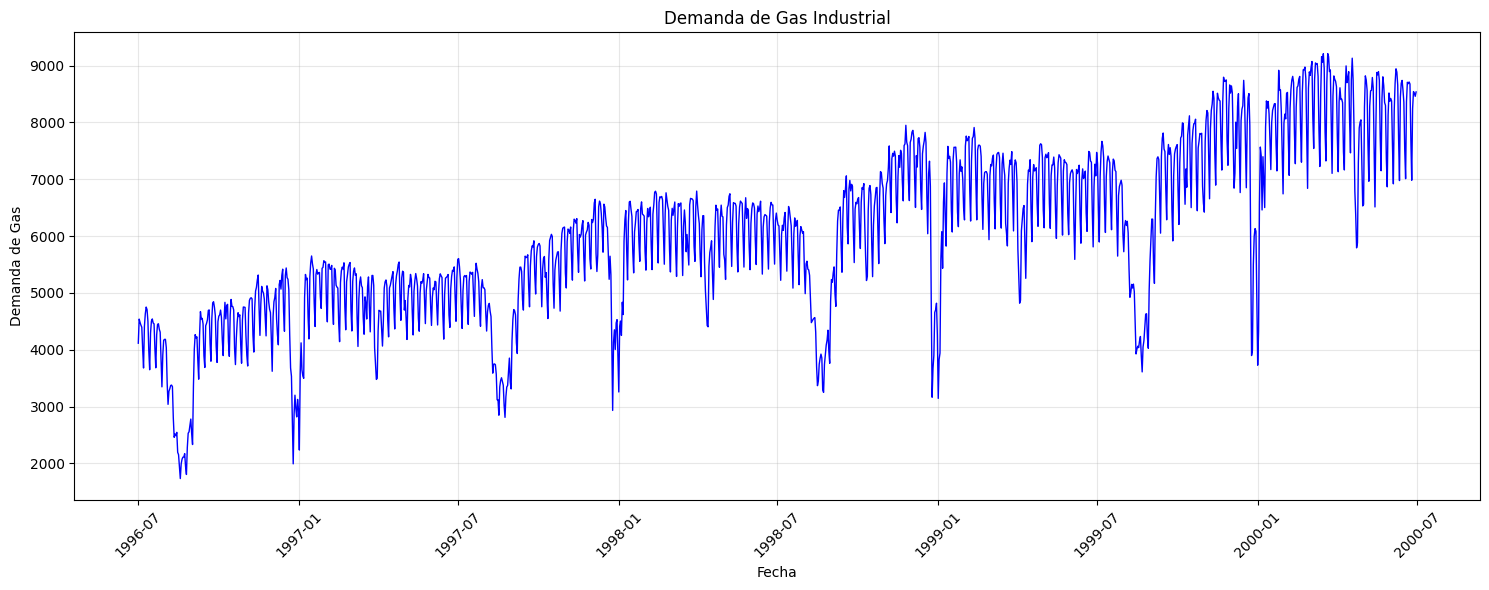

In [4]:
# ===============================
# 3. VISUALIZACIÓN INICIAL
# ===============================

def plot_time_series(df, title="Demanda de Gas Industrial"):
    """Visualiza la serie temporal completa"""
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.plot(df['FECHA'], df['DEMANDA_GAS'], color='blue', linewidth=1)
    ax.set_xlabel('Fecha')
    ax.set_ylabel('Demanda de Gas')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

print("=== VISUALIZACIÓN DE LA SERIE TEMPORAL ===")
plot_time_series(datos)


=== GRÁFICOS MENSUALES ===


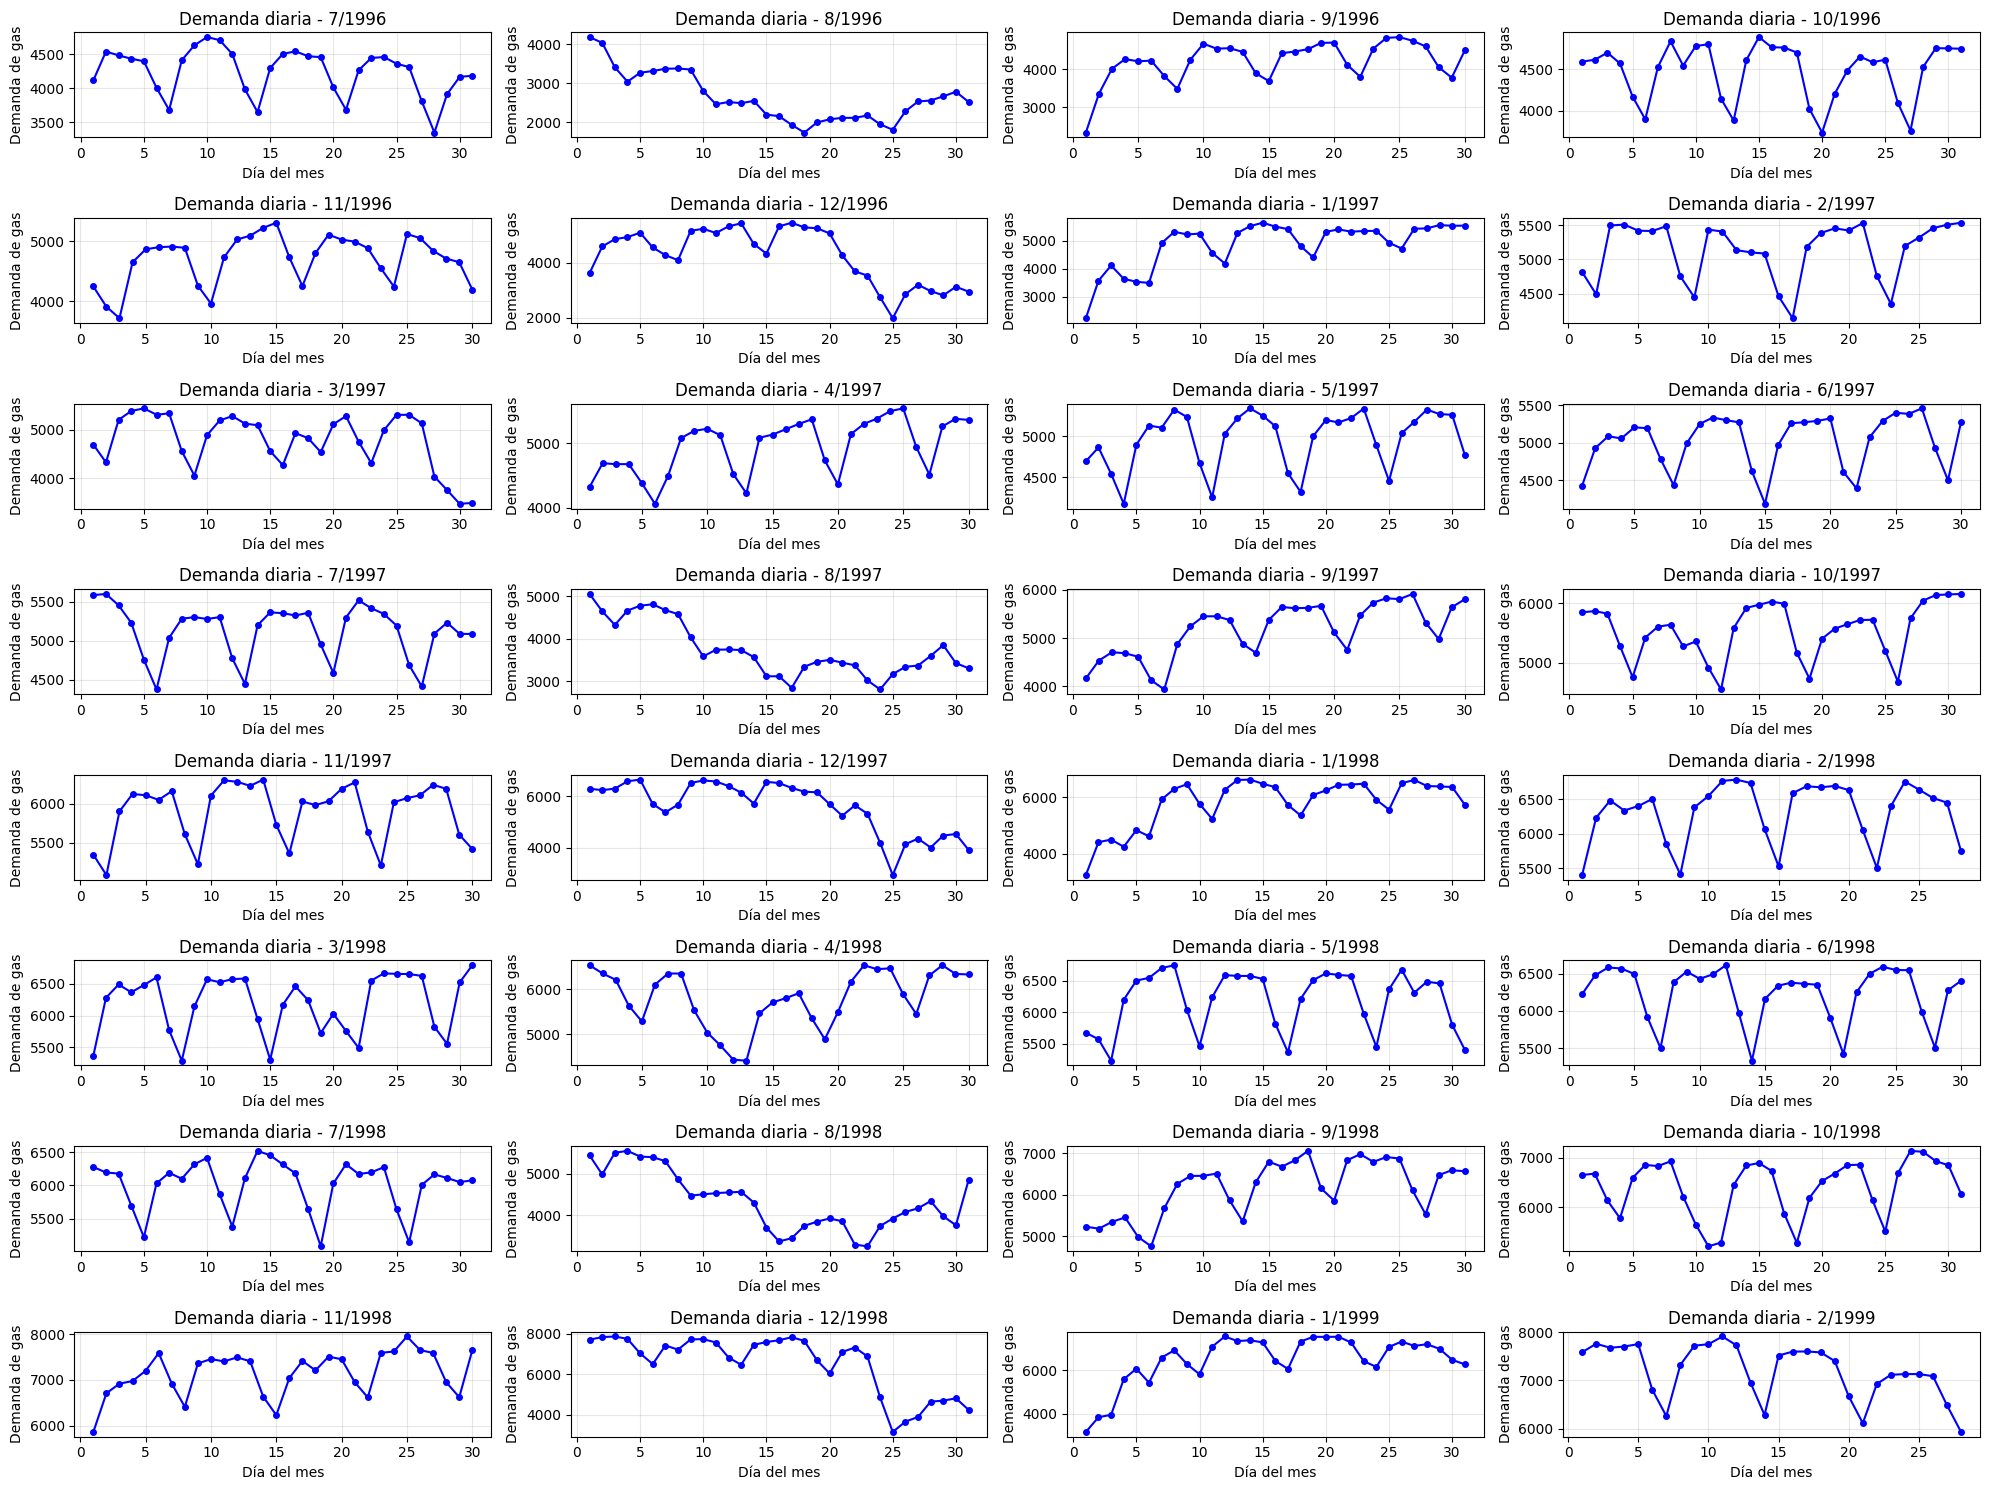

In [5]:

# Gráficos mensuales por año
def plot_monthly_charts(df):
    """Genera gráficos para cada combinación año-mes"""
    combinaciones = df[['ANYO', 'MES']].drop_duplicates()
    
    fig, axes = plt.subplots(8, 4, figsize=(20, 15))#podemos poner más combinaciones de años para ello hay que modificar el combinaciones.head
    axes = axes.flatten()
    
    for i, (_, row) in enumerate(combinaciones.head(32).iterrows()):
        anyo, mes = int(row['ANYO']), int(row['MES'])
        datos_mes = df[(df['ANYO'] == anyo) & (df['MES'] == mes)]
        
        if i < len(axes):
            axes[i].plot(datos_mes['DIAMES'], datos_mes['DEMANDA_GAS'], 
                        'bo-', markersize=4)
            axes[i].set_title(f'Demanda diaria - {mes}/{anyo}')
            axes[i].set_xlabel('Día del mes')
            axes[i].set_ylabel('Demanda de gas')
            axes[i].grid(True, alpha=0.3)
    
    # Ocultar subplots vacíos
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

print("\n=== GRÁFICOS MENSUALES ===")
plot_monthly_charts(datos)


In [6]:

# ===============================
# 4. SEPARACIÓN EN ENTRENAMIENTO Y TEST
# ===============================

def split_train_test(df, split_date='1999-06-30'):
    """Separa los datos en entrenamiento y test"""
    split_date = pd.to_datetime(split_date)
    train = df[df['FECHA'] <= split_date].copy()
    test = df[df['FECHA'] > split_date].copy()
    return train, test

datos_train, datos_test = split_train_test(datos)

print(f"\n=== SEPARACIÓN DE DATOS ===")
print(f"Datos de entrenamiento: {len(datos_train)} observaciones")
print(f"Datos de test: {len(datos_test)} observaciones")


=== SEPARACIÓN DE DATOS ===
Datos de entrenamiento: 1095 observaciones
Datos de test: 366 observaciones


In [36]:

# ===============================
# 5. MODELOS DE REGRESIÓN
# ===============================

class TimeSeriesModels:
    def __init__(self):
        self.models = {}
        self.predictions = {}
        self.mape_scores = {}
    
    def add_time_trend(self, df, reference_date=None):
        """Añade variable de tendencia temporal"""
        df = df.copy()
        if reference_date is None:
            reference_date = df['FECHA'].min()
        df['T'] = (df['FECHA'] - reference_date).dt.days + 1
        return df
    
    def fit_linear_trend_model(self, train_df, test_df=None):
        """Modelo de regresión lineal frente al tiempo"""
        train = self.add_time_trend(train_df)
        
        # Ajustar modelo
        X_train = train[['T']]
        y_train = train['DEMANDA_GAS']
        
        model = LinearRegression()
        model.fit(X_train, y_train)
        
        # Predicciones en entrenamiento
        train_pred = model.predict(X_train)
        train_mape = mean_absolute_percentage_error(y_train, train_pred)
        
        results = {
            'model': model,
            'train_mape': train_mape,
            'formula': f"DEMANDA_GAS = {model.intercept_:.2f} + {model.coef_[0]:.2f} * T"
        }
        
        if test_df is not None:
            test = self.add_time_trend(test_df, train['FECHA'].min())
            X_test = test[['T']]
            y_test = test['DEMANDA_GAS']
            test_pred = model.predict(X_test)
            test_mape = mean_absolute_percentage_error(y_test, test_pred)
            results['test_mape'] = test_mape
        
        self.models['linear_trend'] = results
        return results
    
    def add_lag_variables(self, df, lags):
        """Añade variables lag para modelos autorregresivos"""
        df = df.copy()
        for lag in lags:
            df[f'DEMANDA_GAS_{lag}'] = df['DEMANDA_GAS'].shift(lag)
        return df
    
    def fit_ar_model(self, df, lags, model_name):
        """Ajusta modelo autorregresivo"""
        df_lag = self.add_lag_variables(df, lags)
        df_clean = df_lag.dropna()
        
        # Variables predictoras
        X_cols = [f'DEMANDA_GAS_{lag}' for lag in lags]
        X = df_clean[X_cols]
        y = df_clean['DEMANDA_GAS']
        
        # Ajustar modelo
        model = LinearRegression()
        model.fit(X, y)
        
        # Predicciones
        predictions = model.predict(X)
        mape = mean_absolute_percentage_error(y, predictions)
        
        # Fórmula
        formula_parts = [f"{model.intercept_:.2f}"]
        for i, lag in enumerate(lags):
            formula_parts.append(f"{model.coef_[i]:.2f} * DEMANDA_GAS(t-{lag})")
        formula = "DEMANDA_GAS(t) = " + " + ".join(formula_parts)
        
        results = {
            'model': model,
            'mape': mape,
            'formula': formula,
            'lags': lags,
            'predictions': predictions,
            'actual': y,
            'dates': df_clean['FECHA']
        }
        
        self.models[model_name] = results
        return results
    
    def fit_ar_with_dummy(self, df, lags, dummy_conditions, model_name):
        """Ajusta modelo autorregresivo con variables dummy"""
        df_lag = self.add_lag_variables(df, lags)
        
        # Añadir variables dummy
        for dummy_name, condition in dummy_conditions.items():
            df_lag[dummy_name] = condition(df_lag).astype(int)
        
        df_clean = df_lag.dropna()
        
        # Variables predictoras
        X_cols = [f'DEMANDA_GAS_{lag}' for lag in lags] + list(dummy_conditions.keys())
        X = df_clean[X_cols]
        y = df_clean['DEMANDA_GAS']
        
        # Ajustar modelo
        model = LinearRegression()
        model.fit(X, y)
        
        # Predicciones
        predictions = model.predict(X)
        mape = mean_absolute_percentage_error(y, predictions)
        
        results = {
            'model': model,
            'mape': mape,
            'lags': lags,
            'dummy_vars': list(dummy_conditions.keys()),
            'predictions': predictions,
            'actual': y,
            'dates': df_clean['FECHA']
        }
        
        self.models[model_name] = results
        return results

    def plot_model_comparison(self, df, model_name, last_days=30, start_date=None, end_date=None, y_label="Demanda de Gas"):
        """
        Visualiza resultados de un modelo entre un rango de fechas o, por defecto, los últimos N días.
        Evita desalineaciones creando un DataFrame temporal y filtrando por fecha.
        """
        if model_name not in self.models:
            print(f"Modelo {model_name} no encontrado")
            return
    
        import numpy as np
        import pandas as pd
        from datetime import timedelta
        import matplotlib.pyplot as plt
    
        results = self.models[model_name]
    
        # --- 1) Construir un DataFrame coherente y ordenado por fecha ---
        df_plot = pd.DataFrame({
            "date": pd.to_datetime(results["dates"]),
            "actual": np.asarray(results["actual"], dtype="float64"),
            "pred":   np.asarray(results["predictions"], dtype="float64"),
        }).dropna(subset=["date"])  # por si acaso
        if df_plot.empty:
            print(f"Sin datos para {model_name}.")
            return
    
        df_plot = df_plot.sort_values("date").reset_index(drop=True)
    
        # --- 2) Rango temporal: fechas explícitas o últimos N días ---
        if start_date is not None or end_date is not None:
            start = pd.to_datetime(start_date) if start_date is not None else df_plot["date"].min()
            end   = pd.to_datetime(end_date)   if end_date   is not None else df_plot["date"].max()
        else:
            end = df_plot["date"].max()
            start = end - timedelta(days=last_days)
    
        # --- 3) Filtrado seguro por fecha (incluye extremos) ---
        df_plot = df_plot[(df_plot["date"] >= start) & (df_plot["date"] <= end)]
        if df_plot.empty:
            print(f"No hay datos entre {start.date()} y {end.date()} para el modelo {model_name}.")
            return
    
        # --- 4) Título y MAPE ---
        mape = results.get("mape", np.nan)
        try:
            mape_txt = f" (MAPE: {float(mape):.2%})" if pd.notna(mape) else ""
        except Exception:
            mape_txt = ""
    
        rango_txt = f"{df_plot['date'].min().date()} → {df_plot['date'].max().date()}"
        title = f"Modelo {model_name} - {rango_txt}{mape_txt}"
    
        # --- 5) Gráfico ---
        fig, ax = plt.subplots(figsize=(15, 6))
        ax.plot(df_plot["date"], df_plot["actual"], 'bo-', label='Real', markersize=4)
        ax.plot(df_plot["date"], df_plot["pred"],   'ro-', label='Predicción', markersize=4)
        ax.set_xlabel('Fecha')
        ax.set_ylabel(y_label)
        ax.set_title(title)
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [40]:

# ===============================
# 6. AJUSTE DE MODELOS
# ===============================

ts_models = TimeSeriesModels()

# Combinar datos para algunos modelos
datos_completos = pd.concat([datos_train, datos_test], ignore_index=True)
datos_completos = ts_models.add_time_trend(datos_completos)

print("\n=== AJUSTE DE MODELOS ===")

# 1. Modelo de tendencia lineal
print("\n1. Modelo de regresión lineal frente al tiempo:")
linear_results = ts_models.fit_linear_trend_model(datos_train, datos_test)
print(f"   Fórmula: {linear_results['formula']}")
print(f"   MAPE entrenamiento: {linear_results['train_mape']:.2%}")
if 'test_mape' in linear_results:
    print(f"   MAPE test: {linear_results['test_mape']:.2%}")

# 2. Modelo AR(1)
print("\n2. Modelo AR(1):")
ar1_results = ts_models.fit_ar_model(datos_completos, [1], 'AR1')
print(f"   Fórmula: {ar1_results['formula']}")
print(f"   MAPE: {ar1_results['mape']:.2%}")

# 3. Modelo AR(7)
print("\n3. Modelo AR(7):")
ar7_results = ts_models.fit_ar_model(datos_completos, [7], 'AR7')
print(f"   Fórmula: {ar7_results['formula']}")
print(f"   MAPE: {ar7_results['mape']:.2%}")

# 4. Modelo AR(1,7)
print("\n4. Modelo AR(1,7):")
ar1_7_results = ts_models.fit_ar_model(datos_completos, [1, 7], 'AR1_7')
print(f"   Fórmula: {ar1_7_results['formula']}")
print(f"   MAPE: {ar1_7_results['mape']:.2%}")

# 5. Modelo AR(1,7,8)
print("\n5. Modelo AR(1,7,8):")
ar1_7_8_results = ts_models.fit_ar_model(datos_completos, [1, 7, 8], 'AR1_7_8')
print(f"   Fórmula: {ar1_7_8_results['formula']}")
print(f"   MAPE: {ar1_7_8_results['mape']:.2%}")

# 6. Modelo con variable dummy para festivo
print("\n6. Modelo AR(1,7,8) con dummy festivo:")
dummy_conditions = {
    'fiesta_1999_10_12': lambda df: (df['MES'] == 10) & (df['DIAMES'] == 12)
}
ar_fest_results = ts_models.fit_ar_with_dummy(
    datos_completos, [1, 7, 8], dummy_conditions, 'AR1_7_8_FEST'
)
print(f"   MAPE: {ar_fest_results['mape']:.2%}")



=== AJUSTE DE MODELOS ===

1. Modelo de regresión lineal frente al tiempo:
   Fórmula: DEMANDA_GAS = 3948.36 + 2.89 * T
   MAPE entrenamiento: 13.74%
   MAPE test: 13.44%

2. Modelo AR(1):
   Fórmula: DEMANDA_GAS(t) = 375.93 + 0.94 * DEMANDA_GAS(t-1)
   MAPE: 6.94%

3. Modelo AR(7):
   Fórmula: DEMANDA_GAS(t) = 552.82 + 0.91 * DEMANDA_GAS(t-7)
   MAPE: 7.64%

4. Modelo AR(1,7):
   Fórmula: DEMANDA_GAS(t) = 96.77 + 0.60 * DEMANDA_GAS(t-1) + 0.38 * DEMANDA_GAS(t-7)
   MAPE: 5.86%

5. Modelo AR(1,7,8):
   Fórmula: DEMANDA_GAS(t) = 156.73 + 0.87 * DEMANDA_GAS(t-1) + 0.81 * DEMANDA_GAS(t-7) + -0.71 * DEMANDA_GAS(t-8)
   MAPE: 3.58%

6. Modelo AR(1,7,8) con dummy festivo:
   MAPE: 3.58%



=== VISUALIZACIÓN DE MODELOS ===
AR1


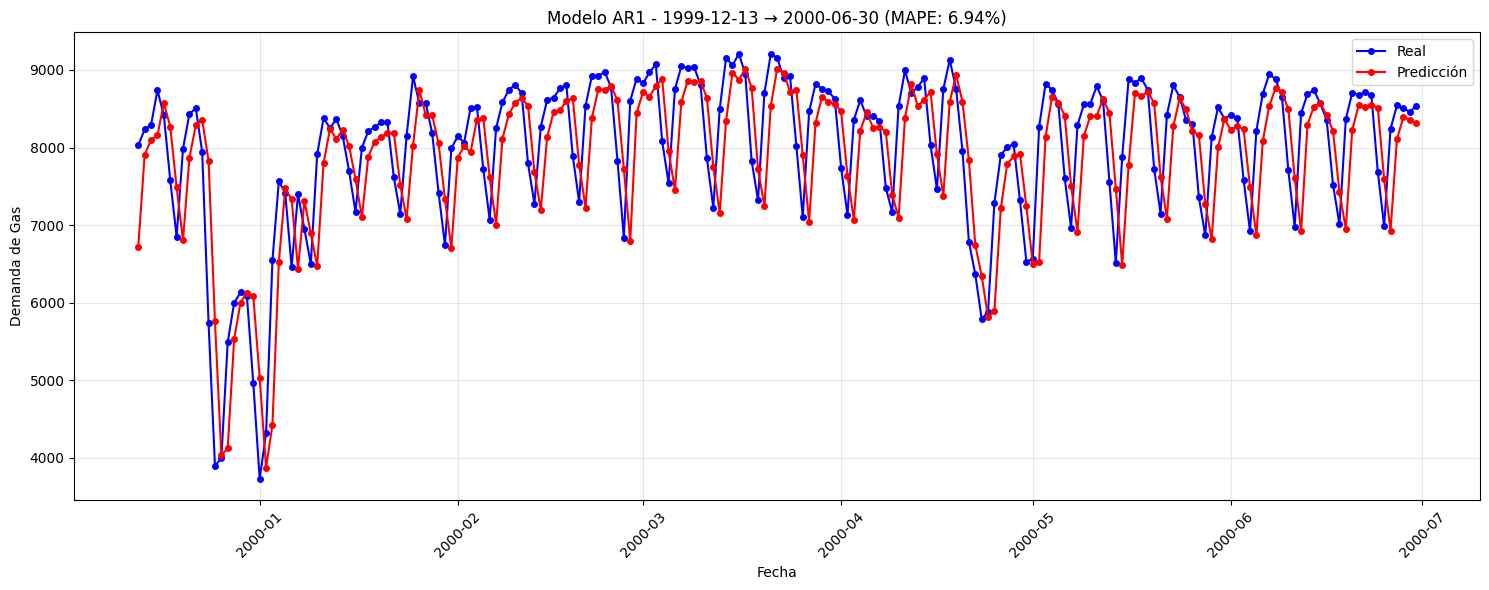

AR7


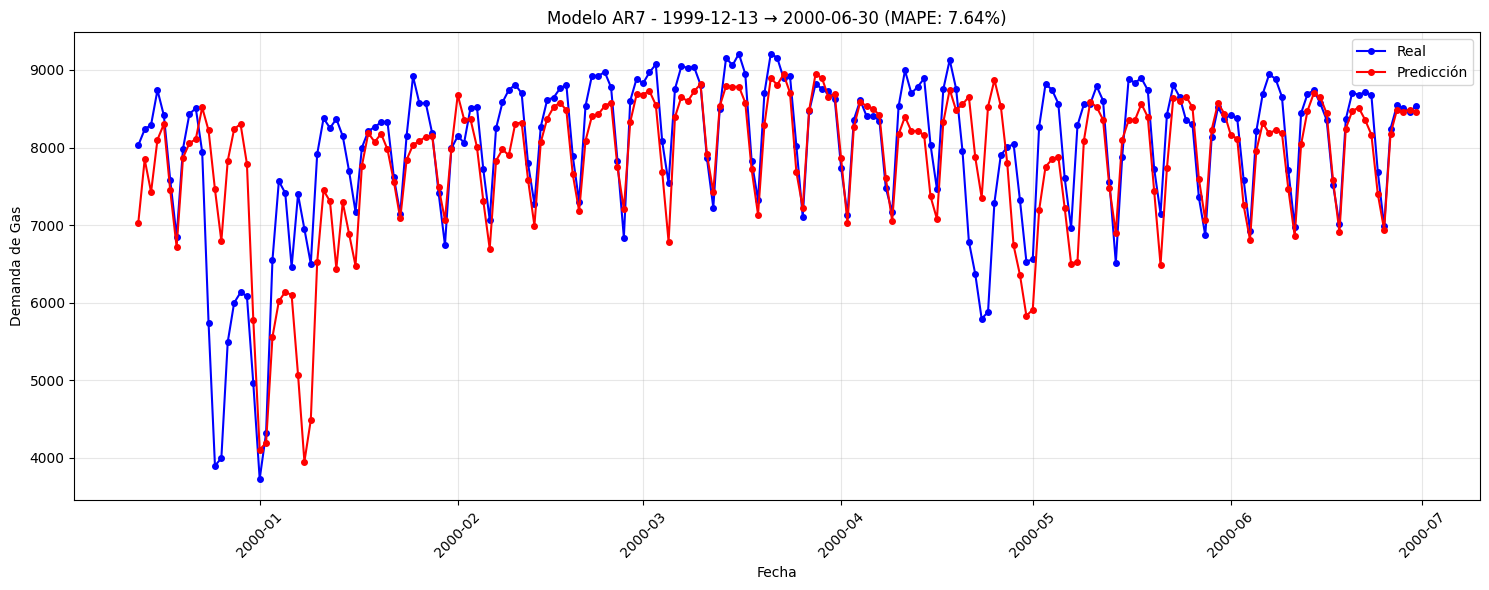

AR1_7


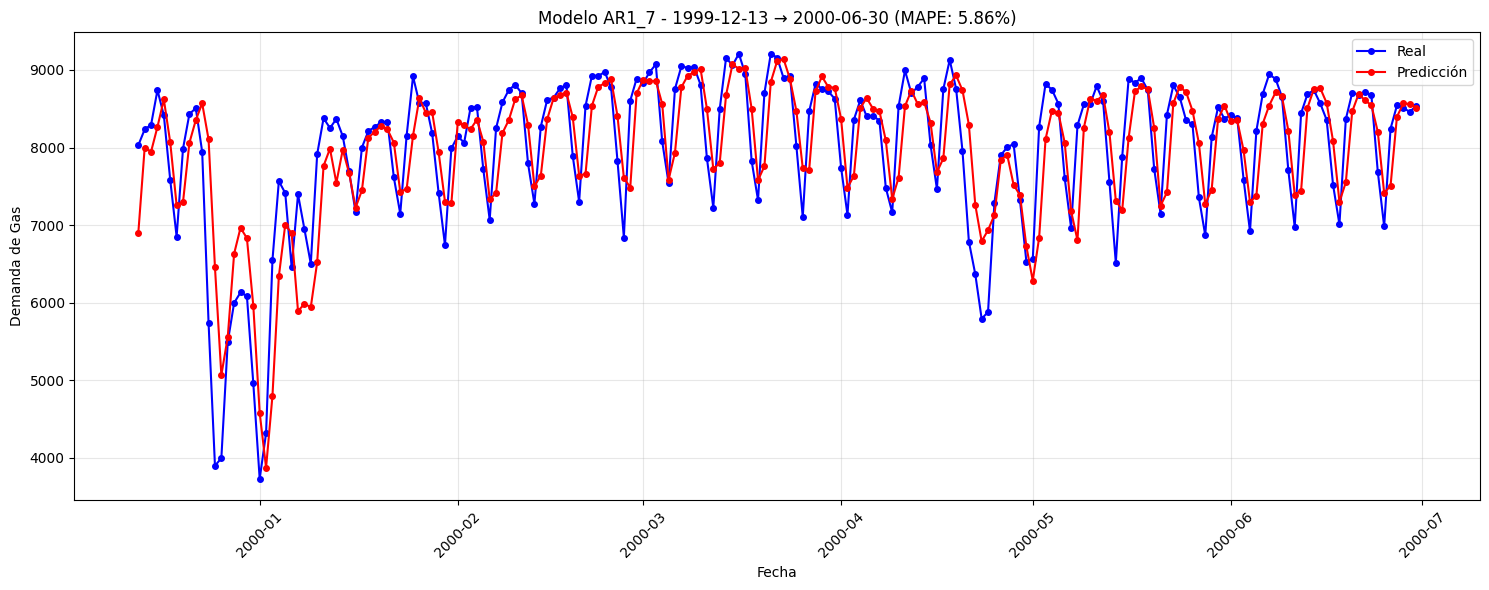

AR1_7_8


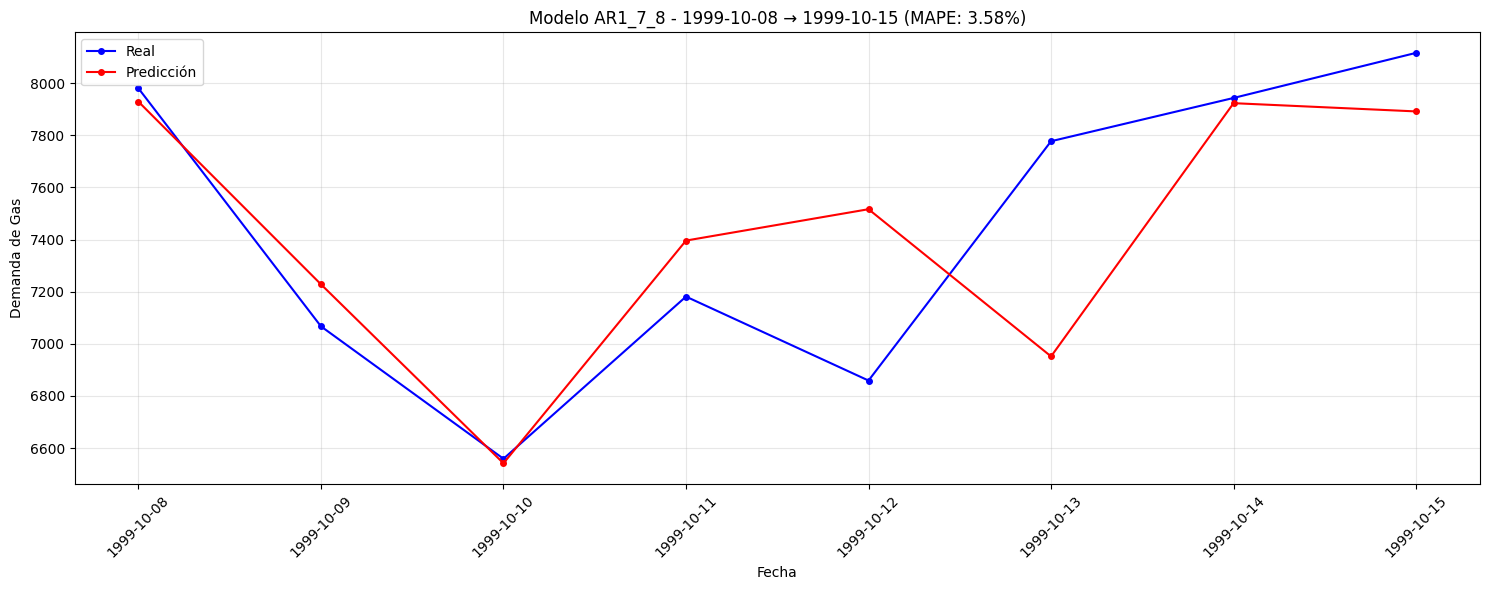

AR1_7_8_FEST


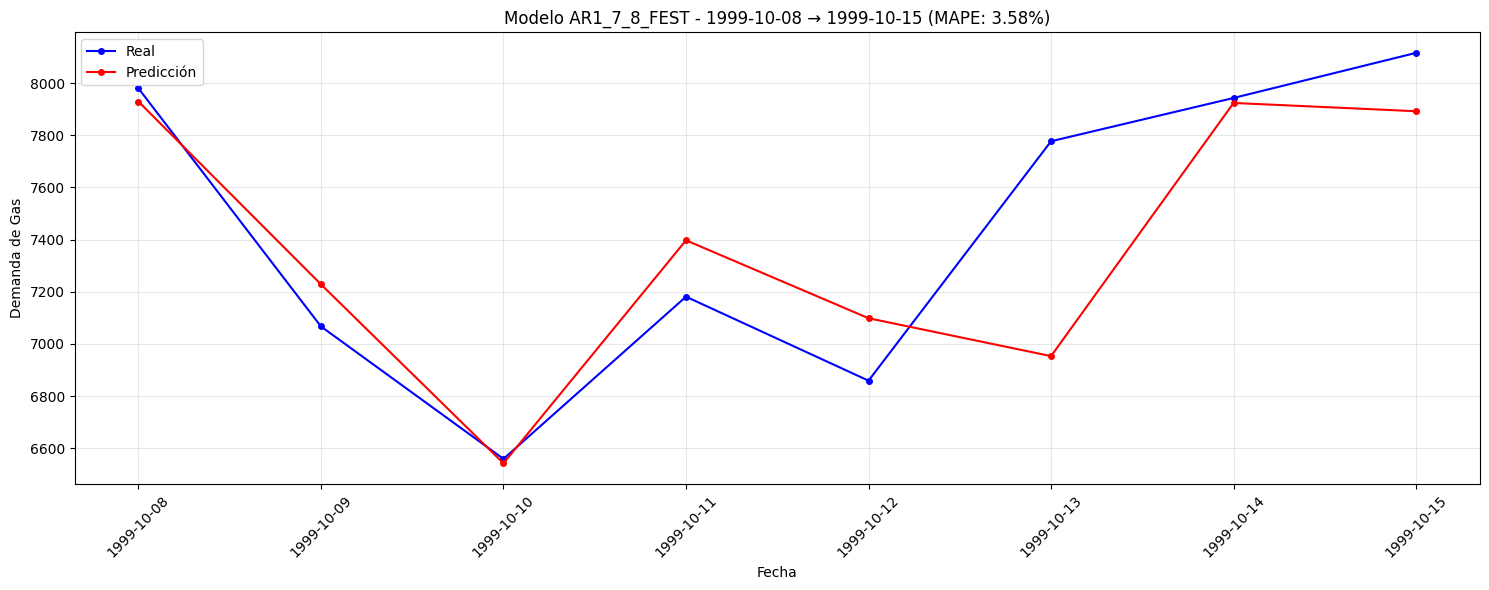

In [39]:

# ===============================
# 7. VISUALIZACIÓN DE RESULTADOS
# ===============================

print("\n=== VISUALIZACIÓN DE MODELOS ===")

# Visualizar diferentes modelos
models_to_plot = ['AR1', 'AR7', 'AR1_7', 'AR1_7_8', 'AR1_7_8_FEST']

#for model_name in models_to_plot:
#    if model_name in ts_models.models:
#        ts_models.plot_model_comparison2(datos_completos, model_name, last_days=200)

for model_name in models_to_plot:
    if model_name in ts_models.models:
        print(model_name)
        if model_name in ['AR1_7_8', 'AR1_7_8_FEST']:
            ts_models.plot_model_comparison(datos_completos, model_name,  start_date="1999-10-08", end_date="1999-10-15")
        else:
            ts_models.plot_model_comparison(datos_completos, model_name, last_days=200)


In [ ]:

# ===============================
# 8. GRÁFICO INTERACTIVO CON PLOTLY
# ===============================

def create_interactive_plot(df, model_results):
    """Crea gráfico interactivo con plotly"""
    fig = go.Figure()
    
    # Datos reales
    fig.add_trace(go.Scatter(
        x=model_results['dates'],
        y=model_results['actual'],
        mode='markers+lines',
        name='Demanda Real',
        line=dict(color='blue', width=2),
        marker=dict(size=4)
    ))
    
    # Predicciones
    fig.add_trace(go.Scatter(
        x=model_results['dates'],
        y=model_results['predictions'],
        mode='markers+lines',
        name='Predicciones',
        line=dict(color='red', width=2, dash='dash'),
        marker=dict(size=4)
    ))
    
    fig.update_layout(
        title=f'Demanda de Gas - Modelo Interactivo (MAPE: {model_results["mape"]:.2%})',
        xaxis_title='Fecha',
        yaxis_title='Demanda de Gas',
        hovermode='x unified',
        width=1000,
        height=500
    )    
    return fig

# Crear gráfico interactivo del mejor modelo
if 'AR1_7_8_FEST' in ts_models.models:
    interactive_fig = create_interactive_plot(datos_completos, ts_models.models['AR1_7_8_FEST'])
    interactive_fig.show()


In [ ]:
interactive_fig.write_html("grafico_interactivo.html", include_plotlyjs="cdn", full_html=True)
print("Abre 'grafico_interactivo.html' para ver la figura.")

In [ ]:

# ===============================
# 9. RESUMEN DE RESULTADOS
# ===============================

def print_model_summary():
    """Imprime resumen de todos los modelos"""
    print("\n" + "="*60)
    print("RESUMEN DE MODELOS Y RENDIMIENTO")
    print("="*60)
    
    model_names = {
        'AR1': 'AR(1) - Solo tendencia',
        'AR7': 'AR(7) - Solo estacionalidad',
        'AR1_7': 'AR(1,7) - Tendencia + estacionalidad',
        'AR1_7_8': 'AR(1,7,8) - Modelo extendido',
        'AR1_7_8_FEST': 'AR(1,7,8) + dummy festivo'
    }
    
    results_summary = []
    for model_key, model_desc in model_names.items():
        if model_key in ts_models.models:
            mape = ts_models.models[model_key]['mape']
            results_summary.append((model_desc, mape))
    
    # Ordenar por MAPE
    results_summary.sort(key=lambda x: x[1])
    
    for i, (desc, mape) in enumerate(results_summary):
        print(f"{i+1:2d}. {desc:<30} MAPE: {mape:6.2%}")
    
    print("\n" + "="*60)
    print(f"MEJOR MODELO: {results_summary[0][0]}")
    print(f"MAPE: {results_summary[0][1]:.2%}")
    print("="*60)

print_model_summary()